# Waste Segregation Image Classifier

Machine Learning Minor Project

Classification:
1. Biodegradable
2. Recyclable
3. Hazardous

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/Waste_Segregation_Project/dataset")

print("Checking dataset folder...\n")

if folder.exists():
    for file in folder.iterdir():
        print(f"{file.name} — {file.stat().st_size / (1024**2):.1f} MB")
else:
    print("Folder not found. We need to locate your ZIP files.")

Checking dataset folder...

garbage_classification.zip — 744.1 MB


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/Waste_Segregation_Project/dataset")

for file in folder.iterdir():
    print(f"{file.name} — {file.stat().st_size / (1024**2):.1f} MB")

garbage_classification.zip — 744.1 MB
NexTech14_Waste_Dataset.zip — 174.1 MB


In [ ]:
import zipfile
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/Waste_Segregation_Project/dataset/NexTech14_Waste_Dataset.zip"
)

extract_path = Path("/content/waste_dataset_nextech14")
extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction complete!")
print("Files and folders in the extracted dataset:")

for item in extract_path.iterdir():
    print(item.name, "—", "Folder" if item.is_dir() else "File")

Extraction complete!
Files and folders in the extracted dataset:
NexTech14_Waste_Dataset — Folder


In [ ]:
from pathlib import Path

dataset_path = Path(
    "/content/waste_dataset_nextech14/NexTech14_Waste_Dataset"
)

print("Dataset contents:\n")

for item in sorted(dataset_path.iterdir()):
    if item.is_dir():
        images = [
            f for f in item.rglob("*")
            if f.is_file() and f.suffix.lower() in
            [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
        ]
        print(f"{item.name}: {len(images)} images")
    else:
        print(f"File: {item.name}")

Dataset contents:

test: 1352 images
train: 6296 images
val: 1348 images


In [ ]:
from pathlib import Path

dataset_path = Path(
    "/content/waste_dataset_nextech14/NexTech14_Waste_Dataset"
)

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    split_path = dataset_path / split

    for folder in sorted(split_path.iterdir()):
        if folder.is_dir():
            count = sum(
                1 for f in folder.rglob("*")
                if f.is_file() and f.suffix.lower()
                in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
            )
            print(f"  {folder.name}: {count}")


TRAIN
  hazardous: 1994
  organic: 2065
  recyclable: 2237

VAL
  hazardous: 427
  organic: 442
  recyclable: 479

TEST
  hazardous: 429
  organic: 443
  recyclable: 480


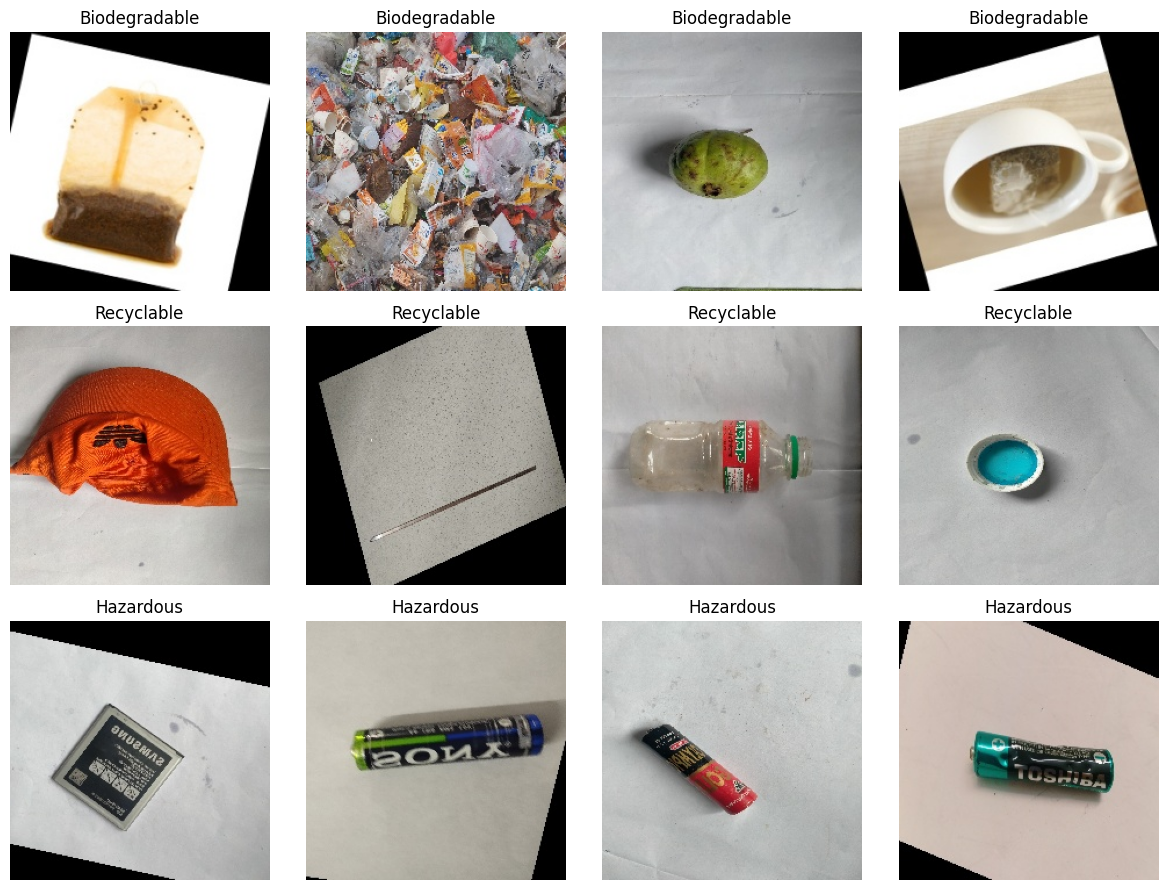

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

dataset_path = Path(
    "/content/waste_dataset_nextech14/NexTech14_Waste_Dataset"
)

categories = {
    "organic": "Biodegradable",
    "recyclable": "Recyclable",
    "hazardous": "Hazardous"
}

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for row, (folder, label) in enumerate(categories.items()):
    image_files = list(
        (dataset_path / "train" / folder).glob("*")
    )
    samples = random.sample(image_files, 4)

    for col, image_path in enumerate(samples):
        img = Image.open(image_path).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

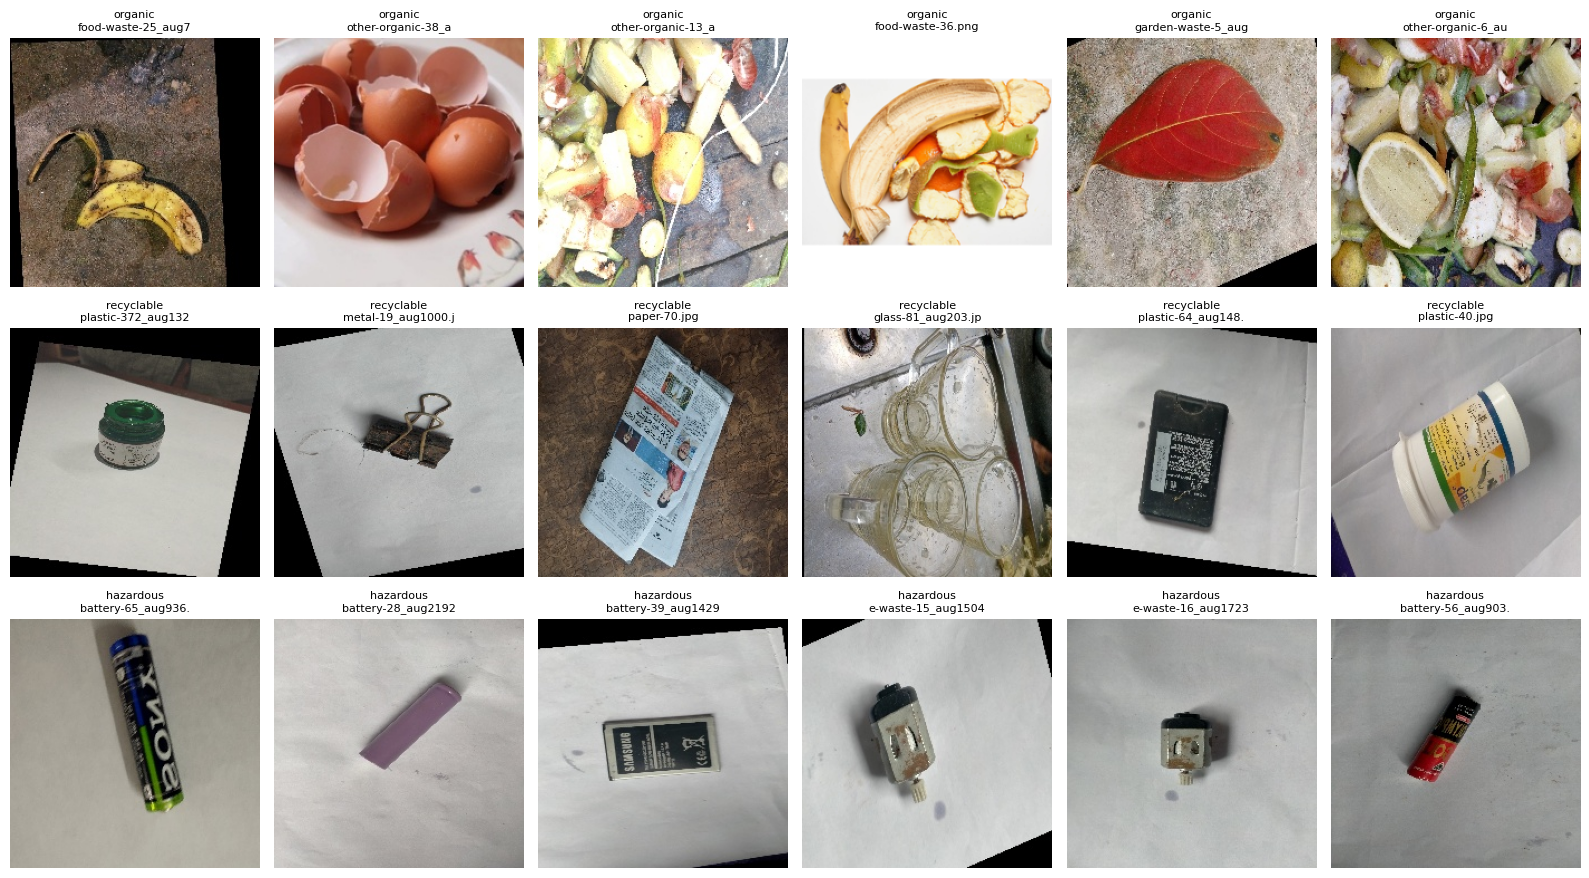

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

base = Path("/content/waste_dataset_nextech14/NexTech14_Waste_Dataset/train")
classes = ["organic", "recyclable", "hazardous"]

fig, axes = plt.subplots(3, 6, figsize=(16, 9))

for row, cls in enumerate(classes):
    files = [
        f for f in (base / cls).iterdir()
        if f.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
    ]

    for col, path in enumerate(random.sample(files, min(6, len(files)))):
        axes[row, col].imshow(Image.open(path).convert("RGB"))
        axes[row, col].set_title(f"{cls}\n{path.name[:18]}", fontsize=8)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

base = Path("/content/waste_dataset_nextech14/NexTech14_Waste_Dataset")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for cls in ["organic", "recyclable", "hazardous"]:
        folder = base / split / cls

        count = sum(
            1 for f in folder.rglob("*")
            if f.is_file() and f.suffix.lower()
            in [".jpg", ".jpeg", ".png", ".webp", ".bmp"]
        )

        print(f"{cls}: {count}")


TRAIN
organic: 2065
recyclable: 2237
hazardous: 1994

VAL
organic: 442
recyclable: 479
hazardous: 427

TEST
organic: 443
recyclable: 480
hazardous: 429


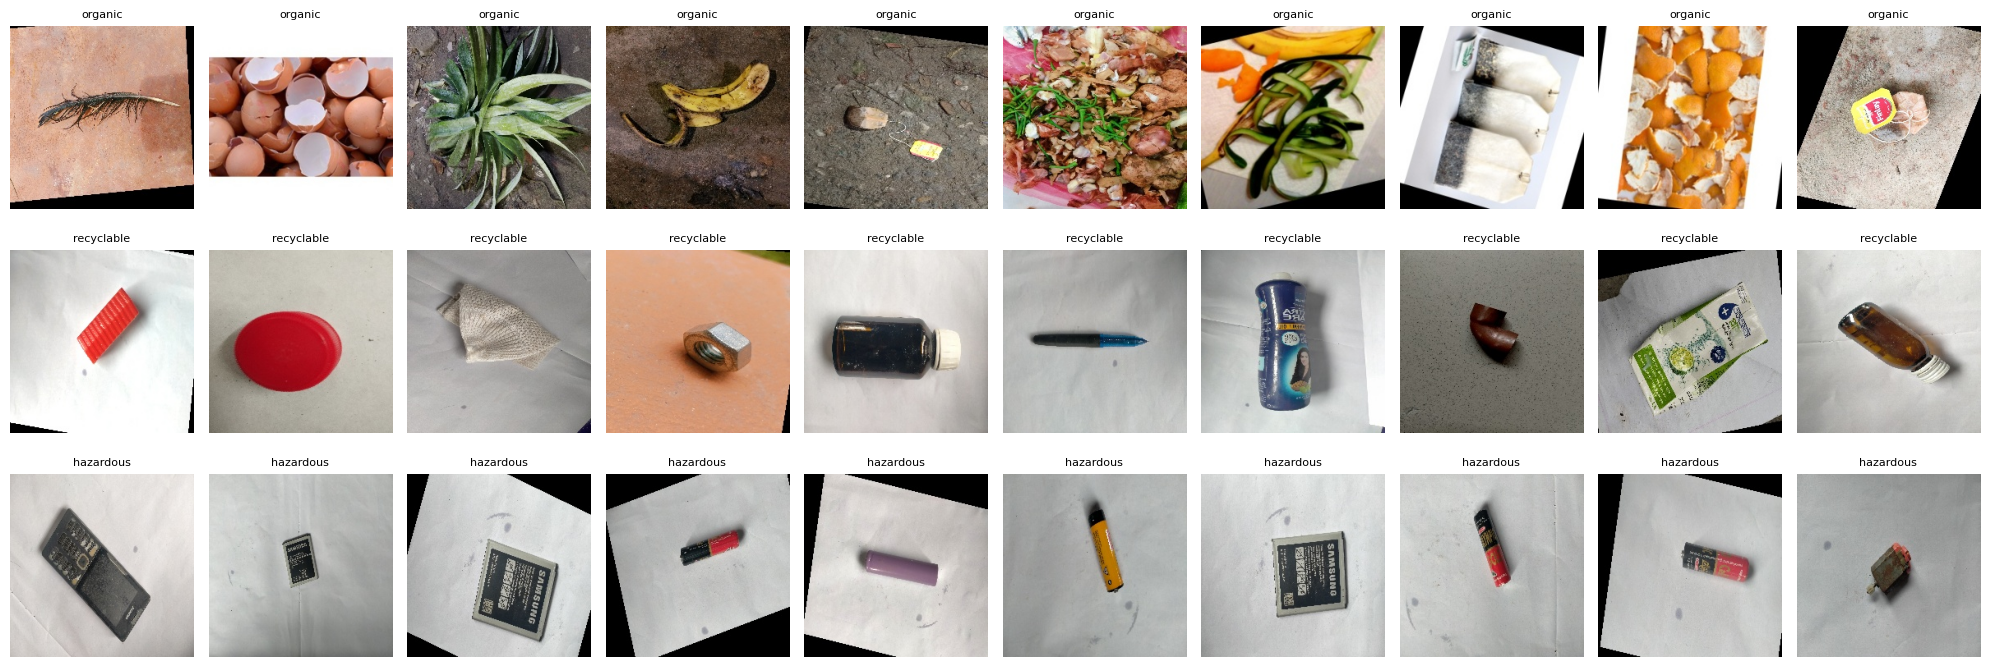

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

base = Path("/content/waste_dataset_nextech14/NexTech14_Waste_Dataset/train")
classes = ["organic", "recyclable", "hazardous"]

fig, axes = plt.subplots(3, 10, figsize=(20, 7))

for row, cls in enumerate(classes):
    files = [
        f for f in (base / cls).rglob("*")
        if f.is_file() and f.suffix.lower()
        in [".jpg", ".jpeg", ".png", ".webp", ".bmp"]
    ]

    for col, path in enumerate(random.sample(files, 10)):
        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(cls, fontsize=8)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from pathlib import Path

DATASET_DIR = Path(
    "/content/waste_dataset_nextech14/NexTech14_Waste_Dataset"
)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("TensorFlow version:", tf.__version__)
print("Dataset folder exists:", DATASET_DIR.exists())
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow version: 2.21.0
Dataset folder exists: True
Image size: (224, 224)
Batch size: 32


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR / "val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

print("\nClass names:", train_ds.class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 6296 files belonging to 3 classes.
Found 1348 files belonging to 3 classes.
Found 1352 files belonging to 3 classes.

Class names: ['hazardous', 'organic', 'recyclable']
Training batches: 197
Validation batches: 43
Test batches: 43


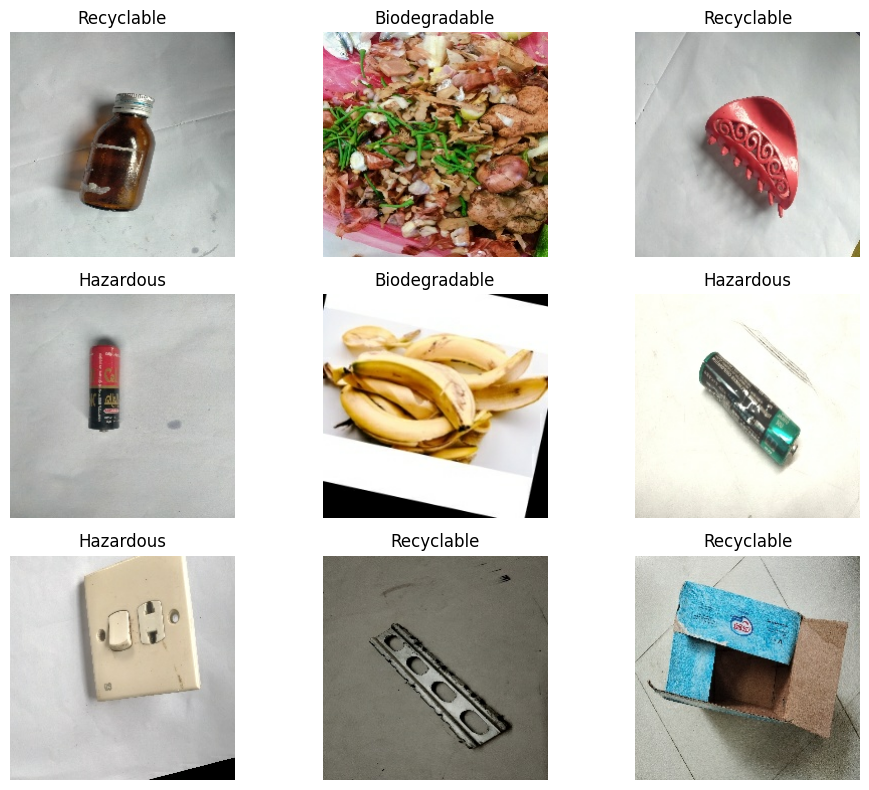

In [ ]:
import matplotlib.pyplot as plt

class_names = train_ds.class_names

images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 8))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))

    class_index = labels[i].numpy().argmax()
    name = class_names[class_index]

    if name == "organic":
        name = "Biodegradable"
    else:
        name = name.capitalize()

    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10)
], name="data_augmentation")

print("Data augmentation is ready!")

Data augmentation is ready!


In [ ]:
num_classes = len(train_ds.class_names)

baseline_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

baseline_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

history_cnn = baseline_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks
)

Epoch 1/3
197/197 ━━━━━━━━━━━━━━━━━━━━ 864s 4s/step - accuracy: 0.6626 - loss: 0.6626 - val_accuracy: 0.6907 - val_loss: 0.6366
Epoch 2/3
197/197 ━━━━━━━━━━━━━━━━━━━━ 863s 4s/step - accuracy: 0.7160 - loss: 0.5927 - val_accuracy: 0.7760 - val_loss: 0.5424
Epoch 3/3
197/197 ━━━━━━━━━━━━━━━━━━━━ 873s 4s/step - accuracy: 0.7392 - loss: 0.5454 - val_accuracy: 0.7671 - val_loss: 0.5316


In [ ]:
test_loss, test_accuracy = baseline_cnn.evaluate(test_ds)

print(f"Baseline CNN Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Baseline CNN Test Loss: {test_loss:.4f}")

43/43 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.7456 - loss: 0.5576
Baseline CNN Test Accuracy: 74.56%
Baseline CNN Test Loss: 0.5576


43/43 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step
               precision    recall  f1-score   support

    Hazardous     0.7378    0.8135    0.7738       429
Biodegradable     0.8512    0.8262    0.8385       443
   Recyclable     0.6526    0.6104    0.6308       480

     accuracy                         0.7456      1352
    macro avg     0.7472    0.7500    0.7477      1352
 weighted avg     0.7447    0.7456    0.7442      1352



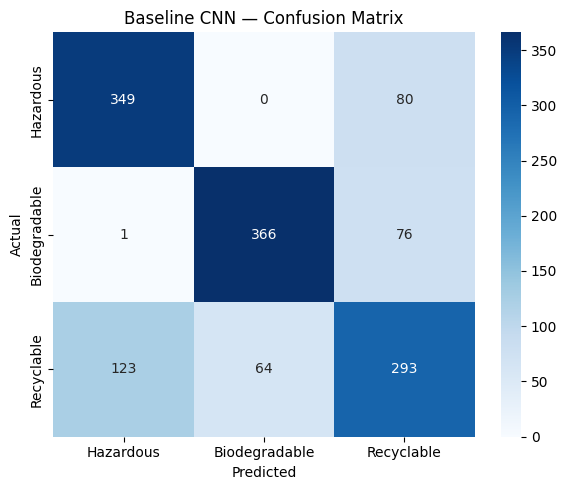

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_true = np.concatenate([
    labels.numpy().argmax(axis=1)
    for images, labels in test_ds
])

y_prob = baseline_cnn.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

display_names = [
    "Hazardous",
    "Biodegradable",
    "Recyclable"
]

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=display_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=display_names,
    yticklabels=display_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Baseline CNN — Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
resnet_base = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

resnet_base.trainable = False

resnet_input = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(resnet_input)
x = tf.keras.applications.resnet50.preprocess_input(x)
x = resnet_base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.3)(x)
resnet_output = tf.keras.layers.Dense(
    num_classes, activation="softmax"
)(x)

resnet_model = tf.keras.Model(resnet_input, resnet_output)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 3)         │        387 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    callbacks=callbacks
)

Epoch 1/2
197/197 ━━━━━━━━━━━━━━━━━━━━ 1704s 9s/step - accuracy: 0.9265 - loss: 0.1992 - val_accuracy: 0.9859 - val_loss: 0.0497
Epoch 2/2
197/197 ━━━━━━━━━━━━━━━━━━━━ 1654s 8s/step - accuracy: 0.9795 - loss: 0.0609 - val_accuracy: 0.9852 - val_loss: 0.0398


In [ ]:
resnet_loss, resnet_accuracy = resnet_model.evaluate(test_ds)

print(f"ResNet50 Test Accuracy: {resnet_accuracy * 100:.2f}%")
print(f"ResNet50 Test Loss: {resnet_loss:.4f}")

43/43 ━━━━━━━━━━━━━━━━━━━━ 288s 7s/step - accuracy: 0.9852 - loss: 0.0450
ResNet50 Test Accuracy: 98.52%
ResNet50 Test Loss: 0.0450


Saving Screenshot 2026-10-12 233651.png to Screenshot 2026-10-12 233651.png


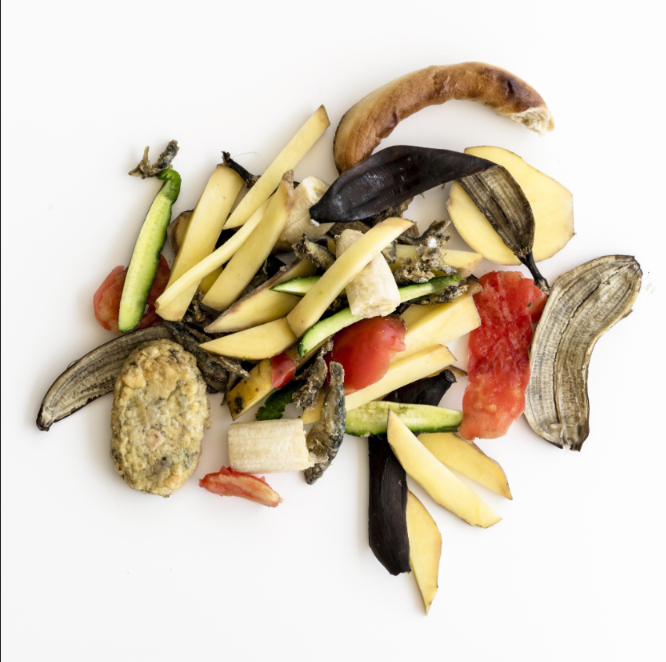

Predicted category: Biodegradable
Confidence: 100.00%


In [ ]:
import numpy as np
from PIL import Image
from google.colab import files
from IPython.display import display

class_names = ["Hazardous", "Biodegradable", "Recyclable"]

uploaded = files.upload()

for filename in uploaded:
    img = Image.open(filename).convert("RGB")
    display(img)

    img = img.resize((224, 224))
    arr = np.array(img, dtype=np.float32)[None, ...]

    predictions = resnet_model.predict(arr, verbose=0)[0]
    index = np.argmax(predictions)

    print("Predicted category:", class_names[index])
    print(f"Confidence: {predictions[index] * 100:.2f}%")

In [ ]:
from pathlib import Path

Path("/content/models").mkdir(exist_ok=True)

resnet_model.save("/content/models/resnet50_waste_classifier.keras")

print("ResNet50 model saved successfully!")

ResNet50 model saved successfully!


In [ ]:
from google.colab import files

files.download("/content/models/resnet50_waste_classifier.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json

results = {
    "project": "Waste Segregation Image Classifier",
    "dataset_images": 8996,
    "classes": [
        "Biodegradable",
        "Recyclable",
        "Hazardous"
    ],
    "baseline_cnn_test_accuracy": 74.56,
    "resnet50_training_epochs": 2,
    "demo_prediction": "Biodegradable",
    "demo_confidence_displayed": "100.00%"
}

with open("/content/project_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Project results saved.")

Project results saved.


In [2]:
import gradio as gr
import numpy as np
from PIL import Image

class_names = ["Hazardous", "Biodegradable", "Recyclable"]

custom_css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
    font-family: Arial, sans-serif;
}
#hero {
    background: linear-gradient(120deg, #123c2c, #23845b);
    color: white;
    padding: 30px;
    border-radius: 20px;
    margin-bottom: 20px;
    text-align: center;
}
#hero h1 {
    font-size: 34px;
    margin-bottom: 8px;
}
#hero p {
    font-size: 16px;
    opacity: 0.95;
}
.panel {
    border: 1px solid #d9e8df;
    border-radius: 18px;
    padding: 18px;
}
#classify {
    background: #218653;
    color: white;
    border: none;
    border-radius: 12px;
    font-size: 17px;
    font-weight: bold;
    min-height: 48px;
}
#classify:hover {
    background: #176a40;
}
#result {
    background: #f0f8f2;
    border-radius: 14px;
    padding: 15px;
    min-height: 100px;
}
#footer {
    text-align: center;
    color: #718078;
    font-size: 13px;
    padding: 16px;
}
"""

def classify_waste(image):
    if image is None:
        return {}, "Please upload an image first."

    image = image.convert("RGB").resize((224, 224))
    array = np.asarray(image, dtype=np.float32)[None, ...]

    predictions = resnet_model.predict(array, verbose=0)[0]
    best_index = int(np.argmax(predictions))
    best_class = class_names[best_index]
    confidence = float(predictions[best_index]) * 100

    results = {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

    message = f"""
### 🌿 Prediction: {best_class}

**Model confidence: {confidence:.2f}%**

{"This item is likely biodegradable." if best_class == "Biodegradable" else "This item is likely recyclable." if best_class == "Recyclable" else "This item may require special handling."}

*This is an AI prediction, not a guarantee. Please follow local waste-disposal rules.*
"""
    return results, message


with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="emerald",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="EcoSort | Waste Classifier"
) as demo:

    gr.HTML("""
    <div id="hero">
        <div style="font-size:42px;">♻️ 🌱</div>
        <h1>EcoSort</h1>
        <p>Smart Waste Segregation using Artificial Intelligence</p>
        <p>Upload a waste photo and discover its predicted category.</p>
    </div>
    """)

    with gr.Row(equal_height=True):
        with gr.Column(scale=1, elem_classes="panel"):
            gr.Markdown("## 📸 Upload your image")
            image_input = gr.Image(
                type="pil",
                label="Waste image",
                height=330
            )
            classify_btn = gr.Button(
                "♻️  Classify Waste",
                elem_id="classify"
            )
            gr.Markdown(
                "**Supported categories**\n\n"
                "🍃 Biodegradable · ♻️ Recyclable · 🔋 Hazardous"
            )

        with gr.Column(scale=1, elem_classes="panel"):
            gr.Markdown("## 🔎 Classification result")
            result_output = gr.Label(
                num_top_classes=3,
                label="Prediction scores"
            )
            message_output = gr.Markdown(
                "Your prediction will appear here.",
                elem_id="result"
            )

    classify_btn.click(
        fn=classify_waste,
        inputs=image_input,
        outputs=[result_output, message_output]
    )

    gr.HTML("""
    <div id="footer">
        EcoSort • Waste Segregation Image Classifier<br>
        A student machine-learning project
    </div>
    """)

demo.launch(share=True)

/tmp/ipykernel_4949/1287004427.py:89: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://50415c45c6ff3f05fc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
